# Task 6: Cancellation and ADR models

The time split follows the assessment brief. Training arrivals end in December 2016; test arrivals run from January through August 2017. September through December 2016 form the validation period. Test data is evaluated after model choices are fixed.


In [1]:
import json
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 110
sns.set_theme(style='whitegrid')

DATA_DIR = Path('../data')
OUTPUT_DIR = Path('../outputs')
SLIDE_DIR = Path('../slides')
MODEL_DIR = Path('../models')
for folder in [DATA_DIR, OUTPUT_DIR, SLIDE_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

from joblib import dump
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (
    average_precision_score, precision_score, recall_score, f1_score,
    confusion_matrix, mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.inspection import permutation_importance


In [2]:
df = pd.read_csv(DATA_DIR / 'hotel_bookings_model_ready.csv', parse_dates=['arrival_date'])
train_full = df['arrival_date'].lt('2017-01-01')
test_mask = df['arrival_date'].ge('2017-01-01')
train_mask = df['arrival_date'].lt('2016-09-01')
val_mask = df['arrival_date'].between('2016-09-01','2016-12-31')
print('Train:', int(train_mask.sum()), 'Validation:', int(val_mask.sum()), 'Test:', int(test_mask.sum()))

categorical = [
    'hotel','meal','market_segment','distribution_channel','reserved_room_type',
    'deposit_type','customer_type','arrival_weekday','lead_time_band','cluster_name'
]
numeric_base = [
    'lead_time','arrival_month','arrival_date_week_number','arrival_date_day_of_month',
    'stays_in_weekend_nights','stays_in_week_nights','total_nights','adults','children','babies',
    'total_guests','has_children','family_booking','weekend_share','is_weekend_arrival',
    'is_repeated_guest','previous_cancellations','previous_bookings_not_canceled',
    'previous_cancel_rate','required_car_parking_spaces','has_parking_request',
    'total_of_special_requests','is_direct_channel'
]
cancellation_numeric = numeric_base + ['adr','price_per_guest']
adr_numeric = numeric_base

leakage = pd.DataFrame([
    ['reservation_status','Directly reveals cancellation, No-Show or Check-Out'],
    ['reservation_status_date','Set after the outcome'],
    ['assigned_room_type','May change after booking'],
    ['booking_changes','Accumulates after booking'],
    ['days_in_waiting_list','Known after booking processing'],
    ['is_canceled','Classification target'],
    ['adr','ADR regression target'],
    ['price_per_guest','Contains ADR target'],
    ['room_revenue_est','Contains ADR and completed nights'],
], columns=['column','reason'])
display(leakage)
leakage.to_csv(OUTPUT_DIR / 'removed_leakage_columns.csv', index=False)

def preprocessor(numeric):
    return ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=20))]), categorical),
    ])


Train: 58723 Validation: 19867 Test: 40619
                    column                                             reason
0       reservation_status  Directly reveals cancellation, No-Show or Chec...
1  reservation_status_date                              Set after the outcome
2       assigned_room_type                           May change after booking
3          booking_changes                          Accumulates after booking
4     days_in_waiting_list                     Known after booking processing
5              is_canceled                              Classification target
6                      adr                              ADR regression target
7          price_per_guest                                Contains ADR target
8         room_revenue_est                  Contains ADR and completed nights


                    column                                             reason
0       reservation_status  Directly reveals cancellation, No-Show or Chec...
1  reservation_status_date                              Set after the outcome
2       assigned_room_type                           May change after booking
3          booking_changes                          Accumulates after booking
4     days_in_waiting_list                     Known after booking processing
5              is_canceled                              Classification target
6                      adr                              ADR regression target
7          price_per_guest                                Contains ADR target
8         room_revenue_est                  Contains ADR and completed nights

## Prediction 1: booking cancellation

PR-AUC is the primary metric because the hotel needs useful ranking across cancellation risk. Precision and recall show the trade-off at a 0.50 model threshold; Task 7 selects the operational threshold from team capacity.


In [3]:
X = df[cancellation_numeric + categorical]
y = df['is_canceled'].astype(int)

classifiers = {
    'Dummy majority': DummyClassifier(strategy='prior'),
    'Logistic regression': LogisticRegression(max_iter=500, class_weight='balanced', random_state=SEED),
    'Random forest': RandomForestClassifier(n_estimators=90, max_depth=16, min_samples_leaf=15, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED),
    'Neural network': MLPClassifier(hidden_layer_sizes=(32,16), max_iter=30, early_stopping=True, batch_size=256, random_state=SEED),
}

validation_rows = []
validation_models = {}
for name, estimator in classifiers.items():
    pipe = Pipeline([('prep', preprocessor(cancellation_numeric)), ('model', estimator)])
    pipe.fit(X.loc[train_mask], y.loc[train_mask])
    prob = pipe.predict_proba(X.loc[val_mask])[:,1]
    pred = (prob >= 0.5).astype(int)
    validation_rows.append({
        'prediction':'Cancellation','split':'Validation','model':name,
        'pr_auc':average_precision_score(y.loc[val_mask], prob),
        'precision':precision_score(y.loc[val_mask], pred, zero_division=0),
        'recall':recall_score(y.loc[val_mask], pred, zero_division=0),
        'f1':f1_score(y.loc[val_mask], pred, zero_division=0),
    })
    validation_models[name] = pipe
    print('Validation complete:', name)
validation_results = pd.DataFrame(validation_rows)
display(validation_results.sort_values('pr_auc', ascending=False))
best_classifier_name = validation_results.loc[validation_results['model'].ne('Dummy majority')].sort_values('pr_auc', ascending=False).iloc[0]['model']


Validation complete: Dummy majority
Validation complete: Logistic regression
Validation complete: Random forest
Validation complete: Neural network
     prediction       split                model  ...  precision    recall        f1
1  Cancellation  Validation  Logistic regression  ...   0.811544  0.589161  0.682699
2  Cancellation  Validation        Random forest  ...   0.919289  0.417052  0.573793
3  Cancellation  Validation       Neural network  ...   0.869250  0.459617  0.601297
0  Cancellation  Validation       Dummy majority  ...   0.000000  0.000000  0.000000

[4 rows x 7 columns]


     prediction       split                model  ...  precision    recall        f1
1  Cancellation  Validation  Logistic regression  ...   0.811544  0.589161  0.682699
2  Cancellation  Validation        Random forest  ...   0.919289  0.417052  0.573793
3  Cancellation  Validation       Neural network  ...   0.869250  0.459617  0.601297
0  Cancellation  Validation       Dummy majority  ...   0.000000  0.000000  0.000000

[4 rows x 7 columns]

In [4]:
test_rows = []
test_models = {}
for name, estimator in classifiers.items():
    pipe = Pipeline([('prep', preprocessor(cancellation_numeric)), ('model', estimator)])
    pipe.fit(X.loc[train_full], y.loc[train_full])
    prob = pipe.predict_proba(X.loc[test_mask])[:,1]
    pred = (prob >= 0.5).astype(int)
    test_rows.append({
        'prediction':'Cancellation','split':'Test','model':name,
        'pr_auc':average_precision_score(y.loc[test_mask], prob),
        'precision':precision_score(y.loc[test_mask], pred, zero_division=0),
        'recall':recall_score(y.loc[test_mask], pred, zero_division=0),
        'f1':f1_score(y.loc[test_mask], pred, zero_division=0),
    })
    test_models[name] = (pipe, prob)
    print('Test complete:', name)
cancellation_test_results = pd.DataFrame(test_rows)
display(cancellation_test_results.sort_values('pr_auc', ascending=False))

best_classifier, best_test_prob = test_models[best_classifier_name]
val_prob = validation_models[best_classifier_name].predict_proba(X.loc[val_mask])[:,1]
capacity_threshold = float(np.quantile(val_prob, 0.75))
best_test_pred = (best_test_prob >= capacity_threshold).astype(int)
print('Selected classifier:', best_classifier_name, 'Capacity threshold:', round(capacity_threshold, 4))
print('Confusion matrix at capacity threshold:')
print(confusion_matrix(y.loc[test_mask], best_test_pred))

cancel_pred = df.loc[test_mask, ['source_row_id','arrival_date','hotel','country','cluster_name','is_canceled']].copy()
cancel_pred['cancellation_probability'] = best_test_prob
cancel_pred['predicted_cancel'] = best_test_pred
cancel_pred.to_csv(OUTPUT_DIR / 'cancellation_test_predictions.csv', index=False)


Test complete: Dummy majority
Test complete: Logistic regression
Test complete: Random forest
Test complete: Neural network
     prediction split                model  ...  precision    recall        f1
2  Cancellation  Test        Random forest  ...   0.748386  0.611351  0.672963
1  Cancellation  Test  Logistic regression  ...   0.715988  0.630164  0.670340
3  Cancellation  Test       Neural network  ...   0.751434  0.582941  0.656550
0  Cancellation  Test       Dummy majority  ...   0.000000  0.000000  0.000000

[4 rows x 7 columns]
Selected classifier: Logistic regression Capacity threshold: 0.6091
Confusion matrix at capacity threshold:
[[22807  2078]
 [ 7512  8222]]


     prediction split                model  ...  precision    recall        f1
2  Cancellation  Test        Random forest  ...   0.748386  0.611351  0.672963
1  Cancellation  Test  Logistic regression  ...   0.715988  0.630164  0.670340
3  Cancellation  Test       Neural network  ...   0.751434  0.582941  0.656550
0  Cancellation  Test       Dummy majority  ...   0.000000  0.000000  0.000000

[4 rows x 7 columns]

## Prediction 2: expected ADR

MAE is the primary metric because it reports the average pricing error in euros. The model excludes ADR-derived features and the flagged extreme ADR record.


In [5]:
reg_df = df[df['adr_extreme_flag'].eq(0) & df['adr'].between(0, 1000)].copy()
reg_train_full = reg_df['arrival_date'].lt('2017-01-01')
reg_test = reg_df['arrival_date'].ge('2017-01-01')
reg_train = reg_df['arrival_date'].lt('2016-09-01')
reg_val = reg_df['arrival_date'].between('2016-09-01','2016-12-31')
Xr = reg_df[adr_numeric + categorical]
yr = reg_df['adr']

regressors = {
    'Dummy mean': DummyRegressor(strategy='mean'),
    'Ridge regression': Ridge(alpha=10.0, solver='lsqr'),
    'Random forest': RandomForestRegressor(n_estimators=100, max_depth=18, min_samples_leaf=8, n_jobs=-1, random_state=SEED),
}
reg_validation_rows = []
for name, estimator in regressors.items():
    pipe = Pipeline([('prep', preprocessor(adr_numeric)), ('model', estimator)])
    pipe.fit(Xr.loc[reg_train], yr.loc[reg_train])
    pred = pipe.predict(Xr.loc[reg_val])
    reg_validation_rows.append({'prediction':'ADR','split':'Validation','model':name,'mae':mean_absolute_error(yr.loc[reg_val], pred),'rmse':mean_squared_error(yr.loc[reg_val], pred)**0.5,'r2':r2_score(yr.loc[reg_val], pred)})
reg_validation_results = pd.DataFrame(reg_validation_rows)
display(reg_validation_results.sort_values('mae'))
best_regressor_name = reg_validation_results.loc[reg_validation_results['model'].ne('Dummy mean')].sort_values('mae').iloc[0]['model']


  prediction       split             model        mae       rmse        r2
2        ADR  Validation     Random forest  21.668975  30.441263  0.458477
1        ADR  Validation  Ridge regression  26.748054  35.205313  0.275717
0        ADR  Validation        Dummy mean  31.164338  41.371175 -0.000201


  prediction       split             model        mae       rmse        r2
2        ADR  Validation     Random forest  21.668975  30.441263  0.458477
1        ADR  Validation  Ridge regression  26.748054  35.205313  0.275717
0        ADR  Validation        Dummy mean  31.164338  41.371175 -0.000201

In [6]:
reg_test_rows = []
reg_models = {}
for name, estimator in regressors.items():
    pipe = Pipeline([('prep', preprocessor(adr_numeric)), ('model', estimator)])
    pipe.fit(Xr.loc[reg_train_full], yr.loc[reg_train_full])
    pred = pipe.predict(Xr.loc[reg_test])
    reg_test_rows.append({'prediction':'ADR','split':'Test','model':name,'mae':mean_absolute_error(yr.loc[reg_test], pred),'rmse':mean_squared_error(yr.loc[reg_test], pred)**0.5,'r2':r2_score(yr.loc[reg_test], pred)})
    reg_models[name] = (pipe, pred)
    print('ADR test complete:', name)
adr_test_results = pd.DataFrame(reg_test_rows)
display(adr_test_results.sort_values('mae'))

best_regressor, best_adr_pred = reg_models[best_regressor_name]
adr_pred = reg_df.loc[reg_test, ['source_row_id','arrival_date','hotel','country','cluster_name','adr']].copy()
adr_pred['predicted_adr'] = best_adr_pred
adr_pred['error'] = adr_pred['predicted_adr'] - adr_pred['adr']
adr_pred.to_csv(OUTPUT_DIR / 'adr_test_predictions.csv', index=False)


ADR test complete: Dummy mean
ADR test complete: Ridge regression
ADR test complete: Random forest
  prediction split             model        mae       rmse        r2
2        ADR  Test     Random forest  22.472996  30.886291  0.648631
1        ADR  Test  Ridge regression  29.640395  41.809453  0.356155
0        ADR  Test        Dummy mean  40.090693  55.652425 -0.140776


  prediction split             model        mae       rmse        r2
2        ADR  Test     Random forest  22.472996  30.886291  0.648631
1        ADR  Test  Ridge regression  29.640395  41.809453  0.356155
0        ADR  Test        Dummy mean  40.090693  55.652425 -0.140776

## Model explanation, weak spots and fairness checks

Permutation importance measures the change in validation performance when each raw feature is shuffled. Error tables compare hotel, segment and high-volume country groups; these groups are monitored rather than used to justify different treatment.


In [7]:
# Permutation importance on fixed samples
rng = np.random.RandomState(SEED)
cls_idx = rng.choice(df.index[val_mask], size=min(3000, int(val_mask.sum())), replace=False)
cls_imp = permutation_importance(validation_models[best_classifier_name], X.loc[cls_idx], y.loc[cls_idx], scoring='average_precision', n_repeats=2, random_state=SEED, n_jobs=-1)
cls_importance = pd.DataFrame({'feature':X.columns,'importance':cls_imp.importances_mean}).sort_values('importance', ascending=False)
cls_importance.to_csv(OUTPUT_DIR / 'cancellation_feature_importance.csv', index=False)

reg_idx = rng.choice(reg_df.index[reg_val], size=min(3000, int(reg_val.sum())), replace=False)
# Refit selected regression model on the earlier training period for validation explanation.
reg_val_model = Pipeline([('prep', preprocessor(adr_numeric)), ('model', regressors[best_regressor_name])])
reg_val_model.fit(Xr.loc[reg_train], yr.loc[reg_train])
reg_imp = permutation_importance(reg_val_model, Xr.loc[reg_idx], yr.loc[reg_idx], scoring='neg_mean_absolute_error', n_repeats=2, random_state=SEED, n_jobs=-1)
reg_importance = pd.DataFrame({'feature':Xr.columns,'importance':reg_imp.importances_mean}).sort_values('importance', ascending=False)
reg_importance.to_csv(OUTPUT_DIR / 'adr_feature_importance.csv', index=False)

def classification_group_table(frame, group):
    rows = []
    for value, g in frame.groupby(group):
        if len(g) < 100:
            continue
        rows.append({
            group:value, 'rows':len(g),
            'prevalence':g['is_canceled'].mean(),
            'precision':precision_score(g['is_canceled'], g['predicted_cancel'], zero_division=0),
            'recall':recall_score(g['is_canceled'], g['predicted_cancel'], zero_division=0),
            'pr_auc':average_precision_score(g['is_canceled'], g['cancellation_probability']),
        })
    return pd.DataFrame(rows)

cancel_group_tables = []
for group in ['hotel','cluster_name','country']:
    t = classification_group_table(cancel_pred, group)
    t['group_type'] = group
    t = t.rename(columns={group:'group_value'})
    cancel_group_tables.append(t)
cancel_errors = pd.concat(cancel_group_tables, ignore_index=True)
cancel_errors.to_csv(OUTPUT_DIR / 'cancellation_group_performance.csv', index=False)

adr_errors = adr_pred.assign(abs_error=lambda x: x['error'].abs()).groupby(['hotel','cluster_name']).agg(rows=('source_row_id','size'), mae=('abs_error','mean'), bias=('error','mean')).reset_index()
adr_errors.to_csv(OUTPUT_DIR / 'adr_group_performance.csv', index=False)

model_results = pd.concat([validation_results, cancellation_test_results, reg_validation_results, adr_test_results], ignore_index=True, sort=False)
model_results.to_csv(OUTPUT_DIR / 'model_results.csv', index=False)

metadata = {
    'random_state': SEED,
    'train_end': '2016-12-31',
    'test_start': '2017-01-01',
    'selected_cancellation_model': best_classifier_name,
    'cancellation_threshold': capacity_threshold,
    'selected_adr_model': best_regressor_name,
}
(OUTPUT_DIR / 'model_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
dump(best_classifier, MODEL_DIR / 'best_cancellation_model.joblib')
dump(best_regressor, MODEL_DIR / 'best_adr_model.joblib')

display(cls_importance.head(10)); display(reg_importance.head(10)); display(cancel_errors.head(20)); display(adr_errors)


                        feature  importance
30                 deposit_type    0.276077
2      arrival_date_week_number    0.088102
1                 arrival_month    0.086340
21    total_of_special_requests    0.071522
27               market_segment    0.065803
33               lead_time_band    0.038681
22            is_direct_channel    0.020361
3     arrival_date_day_of_month    0.018126
20          has_parking_request    0.016367
19  required_car_parking_spaces    0.016027
                     feature  importance
23                     hotel    7.830480
2   arrival_date_week_number    4.214853
25            market_segment    3.762325
10              total_guests    2.693866
27        reserved_room_type    2.199195
24                      meal    1.912193
0                  lead_time    0.843869
6               total_nights    0.455402
28              deposit_type    0.309426
26      distribution_channel    0.153654
                  group_value   rows  ...    pr_auc    group_type

                        feature  importance
30                 deposit_type    0.276077
2      arrival_date_week_number    0.088102
1                 arrival_month    0.086340
21    total_of_special_requests    0.071522
27               market_segment    0.065803
33               lead_time_band    0.038681
22            is_direct_channel    0.020361
3     arrival_date_day_of_month    0.018126
20          has_parking_request    0.016367
19  required_car_parking_spaces    0.016027

                     feature  importance
23                     hotel    7.830480
2   arrival_date_week_number    4.214853
25            market_segment    3.762325
10              total_guests    2.693866
27        reserved_room_type    2.199195
24                      meal    1.912193
0                  lead_time    0.843869
6               total_nights    0.455402
28              deposit_type    0.309426
26      distribution_channel    0.153654

                  group_value   rows  ...    pr_auc    group_type
0                  City Hotel  27446  ...  0.816697         hotel
1                Resort Hotel  13173  ...  0.707872         hotel
2            Long-stay guests  37240  ...  0.791855  cluster_name
3         Loyal repeat guests   1456  ...  0.271715  cluster_name
4   Short-lead standard stays   1914  ...  0.000000  cluster_name
5                         AGO    125  ...  0.925536       country
6                         AUS    233  ...  0.659484       country
7                         AUT    488  ...  0.549825       country
8                         BEL    998  ...  0.578397       country
9                         BRA   1009  ...  0.696844       country
10                        CHE    738  ...  0.599911       country
11                        CHN    434  ...  0.829116       country
12                         CN    638  ...  0.549664       country
13                        DEU   2898  ...  0.508787       country
14        

          hotel               cluster_name   rows        mae       bias
0    City Hotel           Long-stay guests  26419  22.414428 -17.667566
1    City Hotel        Loyal repeat guests    591  14.757841  -3.864338
2    City Hotel  Short-lead standard stays    436  30.515762 -23.939491
3  Resort Hotel             Early planners      9  27.967708 -21.183112
4  Resort Hotel           Long-stay guests  10821  22.259830 -16.242884
5  Resort Hotel        Loyal repeat guests    865  15.604895  -8.127635
6  Resort Hotel  Short-lead standard stays   1478  29.779106 -25.209848

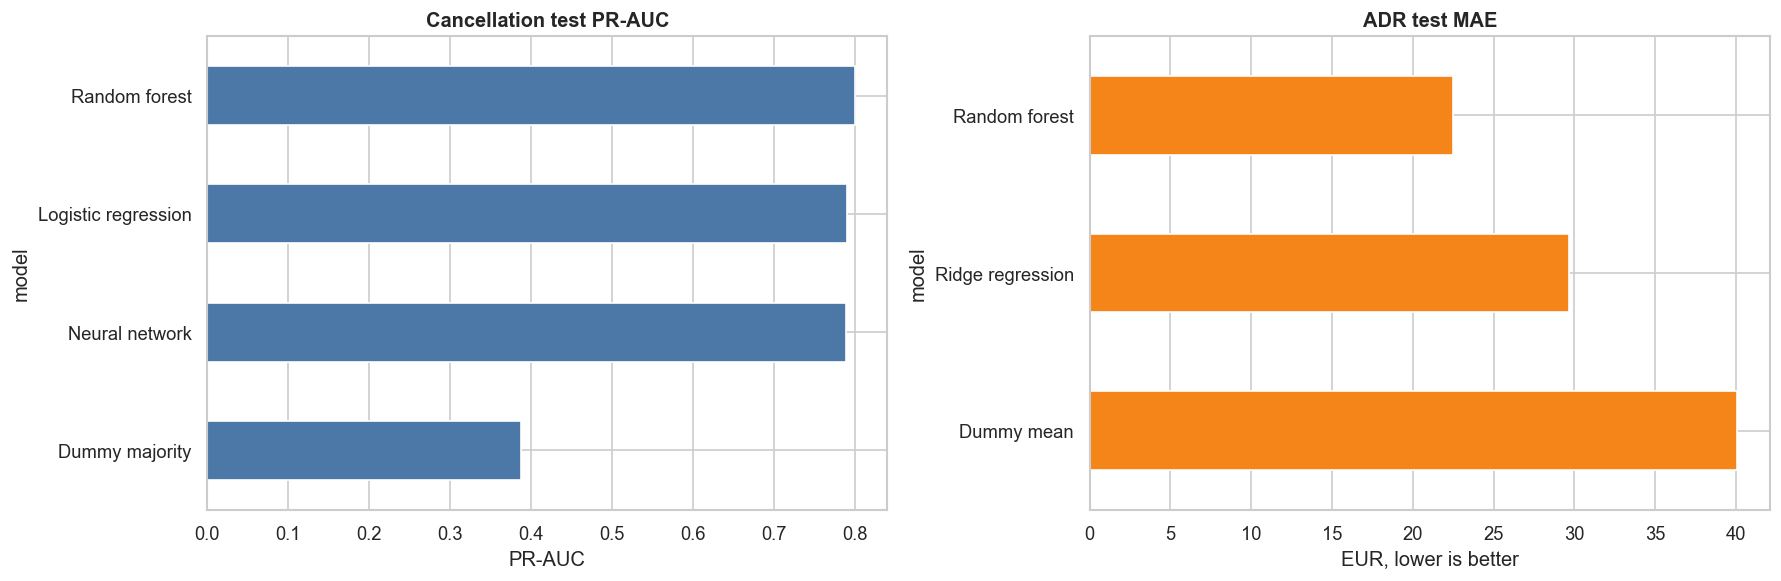

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
cancellation_test_results.set_index('model')['pr_auc'].sort_values().plot.barh(ax=axes[0], color='#4C78A8')
adr_test_results.set_index('model')['mae'].sort_values(ascending=False).plot.barh(ax=axes[1], color='#F58518')
axes[0].set_title('Cancellation test PR-AUC', fontweight='bold'); axes[0].set_xlabel('PR-AUC')
axes[1].set_title('ADR test MAE', fontweight='bold'); axes[1].set_xlabel('EUR, lower is better')
plt.tight_layout(); plt.savefig(SLIDE_DIR / 'model_results_final.png', bbox_inches='tight'); plt.show()
